<a href="https://colab.research.google.com/github/elijahschoeniger-cpu/Walmart-Project-1-/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### REQUIRED SET UP FOR THE NOTEBOOK

In [49]:
import os, time, sqlite3
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

# Get the data
!git clone https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git

# Hurricane Helene landfall date, used for the analysis windows and the charts
LANDFALL = pd.Timestamp('2024-09-26')

fatal: destination path 'Walmart-Project-1-' already exists and is not an empty directory.


In [50]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary

REPO_PATH = globals().get('REPO_PATH', '/content/Walmart-Project-1-/')
DATA = os.path.join(REPO_PATH, 'data')

conn = sqlite3.connect(os.path.join(DATA, 'inventory_and_sales.db'))
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))

DECISIONS = []
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

                  name
0  daily_sales_summary
1     inventory_levels


In [51]:
# Read everything as text so pandas doesn't guess types; we convert explicitly.
NA_TOKENS = ['', 'NULL', 'N/A', 'NaN', 'nan', 'NA', 'None']
raw_txn = pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv'), dtype=str,
                      keep_default_na=False)
raw_stores  = pd.read_csv(os.path.join(DATA, 'store_locations.csv'), dtype=str, keep_default_na=False)
raw_catalog = pd.read_csv(os.path.join(DATA, 'product_catalog.csv'), dtype=str, keep_default_na=False)
raw_dc      = pd.read_csv(os.path.join(DATA, 'distribution_centers.csv'), dtype=str, keep_default_na=False)
raw_sales   = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
raw_inv     = pd.read_sql_query('SELECT * FROM inventory_levels', conn)

# Profile the files read the default way, so blanks/NULL/N/A count as missing
profile(pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv')), 'walmart_transactions')
profile(pd.read_csv(os.path.join(DATA, 'store_locations.csv')), 'store_locations')

=== walmart_transactions ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30
=== store_locations ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id     object      0       0.0        14
store_name   object      0       0.0        12
city         object      0       0.0        12
state        object      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1       7.1        11
region       object      0       0.0         7

e

,dtype,nulls,null_pct,distinct
store_id,object,0,0.0,14
store_name,object,0,0.0,12
city,object,0,0.0,12
state,object,0,0.0,3
zip_code,int64,0,0.0,12
latitude,float64,1,7.1,11
longitude,float64,1,7.1,11
region,object,0,0.0,7


In [52]:
def to_na(s):
    """Strip whitespace and turn every missing-value spelling into a real NaN."""
    s = s.astype(str).str.strip()
    return s.mask(s.isin(NA_TOKENS))

def norm_store_id(s):
    """' FL-330', 'fl_330', 'FL330' -> 'FL-330'."""
    return (s.astype(str).str.strip().str.upper()
             .str.replace(r'^FL[\s_-]?(\d{3})$', r'FL-\1', regex=True))

# 45 SKUs collapse to 20 real products (verified: every SKU's names are variants of one item)
SKU_TO_PRODUCT = {
    'PT-12': 'PT-STRAW', 'SKU#459812': 'PT-STRAW', 'POPTART-STRAW': 'PT-STRAW', 'PT_STRAWBERRY': 'PT-STRAW',
    'WTR-24': 'WATER-24', 'WATER24PK': 'WATER-24', 'WTR_24PK': 'WATER-24',
    'BATT-100': 'BATT-AA4', 'BAT-AA4': 'BATT-AA4', 'BATT_AA_4PK': 'BATT-AA4',
    'FLASH-01': 'FLASHLIGHT', 'LED-FLASH': 'FLASHLIGHT',
    'BEER-24': 'BEER-24', 'LTBEER24': 'BEER-24',
    'BG-MONO': 'MONOPOLY', 'MONOPOLY-01': 'MONOPOLY', 'GAME-MONO': 'MONOPOLY',
    'CARDS-01': 'CARDS', 'PLAYCARD-STD': 'CARDS',
    'STREAM-01': 'STREAMING', 'ROKU-STD': 'STREAMING',
    'SOUP-CAN': 'SOUP', 'CNSOUP-01': 'SOUP',
    'BREAD-WH': 'BREAD', 'WHITEBREAD': 'BREAD',
    'PB-16': 'PB-16', 'PNUTBTR-16': 'PB-16',
    'CNDL-EM': 'CANDLES', 'CANDLE-EMRG': 'CANDLES',
    'FAID-01': 'FIRSTAID', 'FIRSTAID-KIT': 'FIRSTAID',
    'CHRG-PORT': 'CHARGER', 'PORTCHARGER': 'CHARGER',
    'CHIPS-VP': 'CHIPS-VP', 'CHIPVARIETY': 'CHIPS-VP',
    'PTOWEL-6': 'PTOWEL-6', 'PAPERTOWEL6': 'PTOWEL-6',
    'TP-12': 'TP-12', 'TOILETPAPER12': 'TP-12',
    'DIAP-S3': 'DIAPERS-3', 'DIAPERS-3': 'DIAPERS-3',
    'BFORM-01': 'FORMULA', 'BABYFORMULA': 'FORMULA',
    'TARP-HD': 'TARP', 'HDTARP-01': 'TARP',
}
PRODUCTS = pd.DataFrame([
    ('PT-STRAW',  'Pop-Tarts Strawberry',     'Breakfast'),
    ('WATER-24',  'Bottled Water 24-Pack',    'Emergency'),
    ('BATT-AA4',  'AA Batteries 4-Pack',      'Emergency'),
    ('FLASHLIGHT','LED Flashlight',           'Emergency'),
    ('CANDLES',   'Emergency Candles',        'Emergency'),
    ('TARP',      'Heavy Duty Tarp',          'Emergency'),
    ('BEER-24',   'Light Beer 24-Pack',       'Alcohol'),
    ('MONOPOLY',  'Monopoly Board Game',      'Entertainment'),
    ('CARDS',     'Playing Cards',            'Entertainment'),
    ('STREAMING', 'Roku Streaming Stick',     'Electronics'),
    ('CHARGER',   'Portable Phone Charger',   'Electronics'),
    ('SOUP',      'Canned Soup',              'Grocery'),
    ('BREAD',     'White Bread',              'Grocery'),
    ('PB-16',     'Peanut Butter 16oz',       'Grocery'),
    ('FIRSTAID',  'First Aid Kit',            'Health'),
    ('CHIPS-VP',  'Chips Variety Pack',       'Snacks'),
    ('PTOWEL-6',  'Paper Towels 6-Roll',      'Household'),
    ('TP-12',     'Toilet Paper 12-Roll',     'Household'),
    ('DIAPERS-3', 'Diapers Size 3',           'Baby'),
    ('FORMULA',   'Baby Formula',             'Baby'),
], columns=['product_id', 'product', 'category_clean'])

# Messy category text -> the same 10 categories the database already uses
CATEGORY_MAP = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}
def norm_category(s):
    return s.astype(str).str.strip().str.lower().map(CATEGORY_MAP)

In [53]:
txn = raw_txn.copy()
n0 = len(txn)

# 2a. exact duplicates
dups = txn.duplicated().sum()
txn = txn.drop_duplicates().reset_index(drop=True)
log('txn_duplicates', 'Dropped exact duplicate rows (dup transaction_ids were all exact copies)', dups)
assert txn.transaction_id.is_unique

# 2b. store ids
before = txn.store_id.copy()
txn['store_id'] = norm_store_id(txn.store_id)
log('txn_store_id', "Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash)",
    (before != txn.store_id).sum())
assert txn.store_id.str.fullmatch(r'FL-\d{3}').all() and txn.store_id.nunique() == 12

# 2c. timestamps — 5 formats; parse each explicitly so nothing gets guessed wrong
ts = to_na(txn.timestamp)
n_missing_ts = ts.isna().sum()
FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
           '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']
parsed = pd.Series(pd.NaT, index=ts.index, dtype='datetime64[ns]')
for fmt in FORMATS:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
unparsed = (ts.notna() & parsed.isna()).sum()
assert unparsed == 0, f'{unparsed} timestamps matched no known format'
txn['timestamp'] = parsed
log('txn_timestamp', 'Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime', len(txn) - n_missing_ts)
log('txn_timestamp_missing', "Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing",
    n_missing_ts)
txn['ts_missing'] = txn.timestamp.isna()
assert txn.timestamp.dropna().between('2024-09-01', '2024-10-01').all()

# Timezone: POS times are local store time. Pensacola (FL-710) is in Central time; every other store is Eastern.
# timestamp_utc is what to join to the weather API data.
CENTRAL = {'FL-710'}
txn['tz'] = np.where(txn.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
txn['timestamp_utc'] = pd.concat([
    g.timestamp.dt.tz_localize(tz, ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
    for tz, g in txn.groupby('tz')
]).sort_index()
log('txn_timezone', 'Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join',
    txn.timestamp_utc.notna().sum())
txn['date'] = txn.timestamp.dt.normalize()
txn['hour'] = txn.timestamp.dt.hour

# 2d. prices: '$8.26', ' 3.43 ' -> 8.26, 3.43
txn['unit_price'] = pd.to_numeric(txn.unit_price.str.replace(r'[$,\s]', '', regex=True), errors='raise')
log('txn_unit_price', "Stripped '$' and whitespace from unit_price, cast to float",
    raw_txn.unit_price.str.contains(r'[$\s]', regex=True).sum())

# 2e. quantity + negatives
txn['quantity'] = pd.to_numeric(txn.quantity, errors='raise').astype(int)
txn['is_return'] = txn.quantity < 0
log('txn_negative_qty', 'Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0',
    txn.is_return.sum())
txn['line_total'] = (txn.quantity * txn.unit_price).round(2)

# 2f. SKUs -> canonical product; categories from the product (not the messy text)
txn['sku'] = txn.sku.str.strip()
txn['product_id'] = txn.sku.map(SKU_TO_PRODUCT)
assert txn.product_id.notna().all(), 'unmapped SKU'
txn = txn.merge(PRODUCTS, on='product_id', how='left')
log('txn_sku_consolidation', f'Mapped {txn.sku.nunique()} SKUs / {raw_txn.product_name.nunique()} name variants -> {txn.product_id.nunique()} products',
    len(txn))

cat_from_text = norm_category(txn.category)
mismatch = (cat_from_text != txn.category_clean).sum()
assert cat_from_text.notna().all(), 'unmapped category spelling'
log('txn_category', f'Collapsed {raw_txn.category.nunique()} category spellings -> 10; product-derived category disagrees with text in {mismatch} rows',
    len(txn))
txn = txn.rename(columns={'product_name': 'product_name_raw', 'category': 'category_raw'})
txn = txn.rename(columns={'category_clean': 'category'})

print(f'\ntransactions: {n0:,} -> {len(txn):,} rows')
txn.head()

[txn_duplicates] Dropped exact duplicate rows (dup transaction_ids were all exact copies) (30 row(s))
[txn_store_id] Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash) (4345 row(s))
[txn_timestamp] Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime (24648 row(s))
[txn_timestamp_missing] Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing (884 row(s))
[txn_timezone] Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join (24648 row(s))
[txn_unit_price] Stripped '$' and whitespace from unit_price, cast to float (4332 row(s))
[txn_negative_qty] Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0 (130 row(s))
[txn_sku_consolidation] Mapped 45 SKUs / 63 name variants -> 20 products (25532 row(s))
[txn_category] Collapsed 37 category spellings -> 10; product-derived category disagrees wit

,transaction_id,store_id,timestamp,sku,product_name_raw,category_raw,quantity,unit_price,ts_missing,tz,timestamp_utc,date,hour,is_return,line_total,product_id,product,category
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,America/Chicago,2024-09-24 14:48:13+00:00,2024-09-24,9.0,False,3.15,PB-16,Peanut Butter 16oz,Grocery
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,False,America/New_York,2024-09-14 00:30:20+00:00,2024-09-13,20.0,False,2.02,SOUP,Canned Soup,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,False,America/New_York,2024-09-17 14:06:00+00:00,2024-09-17,10.0,False,20.94,TP-12,Toilet Paper 12-Roll,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,False,America/New_York,2024-09-11 10:29:08+00:00,2024-09-11,6.0,False,28.59,STREAMING,Roku Streaming Stick,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,False,America/New_York,2024-09-26 19:59:42+00:00,2024-09-26,15.0,False,56.46,BEER-24,Light Beer 24-Pack,Alcohol


In [54]:
stores = raw_stores.copy()
stores['store_id'] = norm_store_id(stores.store_id)
for c in stores.columns:
    stores[c] = to_na(stores[c])
dups = stores.duplicated('store_id').sum()
stores = stores.drop_duplicates('store_id').reset_index(drop=True)
log('stores_duplicates', "Dropped duplicate stores that only differed by id format (FL239, FL_287)", dups)

bad_state = (stores.state != 'FL').sum()
stores['state'] = 'FL'
log('stores_state', "Standardized state ('Florida', 'Fla.') -> 'FL'", bad_state)

stores['zip_code'] = stores.zip_code.str.zfill(5)
stores[['latitude', 'longitude']] = stores[['latitude', 'longitude']].astype(float)
miss = stores.latitude.isna()
# Tallahassee city-center coordinates — needed for the weather API call and the map
stores.loc[stores.store_id == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
log('stores_coords', 'Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup)', miss.sum())

stores['region'] = stores.region.str.strip().str.title()
stores['tz'] = np.where(stores.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
assert stores.store_id.nunique() == 12 and set(stores.store_id) == set(txn.store_id)
stores

[stores_duplicates] Dropped duplicate stores that only differed by id format (FL239, FL_287) (2 row(s))
[stores_state] Standardized state ('Florida', 'Fla.') -> 'FL' (3 row(s))
[stores_coords] Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup) (1 row(s))


,store_id,store_name,city,state,zip_code,latitude,longitude,region,tz
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West,America/New_York
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South,America/New_York
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North,America/New_York
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central,America/New_York
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East,America/New_York
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West,America/New_York
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North,America/New_York
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,30.4383,-84.2807,Panhandle,America/New_York
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,FL,33701,27.7676,-82.6403,West,America/New_York


In [55]:
catalog = raw_catalog.copy()
for c in catalog.columns:
    catalog[c] = to_na(catalog[c])
catalog['product_id'] = catalog.sku.map(SKU_TO_PRODUCT)
assert catalog.product_id.notna().all()
catalog = catalog.merge(PRODUCTS, on='product_id', how='left')
catalog['category_raw'] = catalog.pop('category')
catalog = catalog.rename(columns={'category_clean': 'category', 'product_name': 'product_name_raw'})

catalog['unit_cost'] = pd.to_numeric(catalog.unit_cost)
miss = catalog.unit_cost.isna()
catalog['unit_cost_imputed'] = miss
catalog['unit_cost'] = catalog.unit_cost.fillna(catalog.groupby('product_id').unit_cost.transform('median'))
log('catalog_unit_cost', 'Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed', miss.sum())
log('catalog_supplier_pkg', 'supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze', len(catalog))
catalog

[catalog_unit_cost] Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed (5 row(s))
[catalog_supplier_pkg] supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze (45 row(s))


,sku,product_name_raw,subcategory,unit_cost,supplier,package_size,product_id,product,category,category_raw,unit_cost_imputed
0,PT-12,pop-tarts strawberry,NaN,1.930,Johnson & Johnson,4-pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast Foods,False
1,SKU#459812,Strawberry Pop-Tart,Pop-Tarts,2.260,Roku Inc,4pk,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
2,POPTART-STRAW,Pop-Tarts Strawberry,NaN,2.110,Sara Lee,6 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
3,PT_STRAWBERRY,pop-tarts strawberry,Pop-Tarts,2.110,Campbell's,4 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,breakfast,True
4,WTR-24,BOTTLED WATER 24PK,Bottled,2.640,Sara Lee,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency Supplies,False
5,WATER24PK,Bottled Water 24-Pack,Bottled,2.380,Sara Lee,24 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
6,WTR_24PK,Water - 24 Pack,NaN,2.080,Frito-Lay,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
7,BATT-100,BATTERIES AA 4PK,AA,3.935,3M Company,6 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,True
8,BAT-AA4,AA Batteries 4-Pack,AA,4.160,Kimberly-Clark,4pk,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,False
9,BATT_AA_4PK,AA Batteries 4-Pack,AA,3.710,Anheuser-Busch,24 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency,False


In [56]:
dc = raw_dc.copy()
for c in dc.columns:
    dc[c] = to_na(dc[c])
dc['surge_capacity_approx'] = dc.surge_capacity.str.contains('~', na=False)
dc['surge_capacity'] = pd.to_numeric(dc.surge_capacity.str.replace('~', '', regex=False))
log('dc_surge_capacity', "Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx", dc.surge_capacity_approx.sum())
for c in ['avg_daily_shipments', 'distance_to_orlando_mi', 'cost_per_shipment']:
    dc[c] = pd.to_numeric(dc[c])
log('dc_cost_missing', 'DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows)',
    dc.cost_per_shipment.isna().sum())
dc

[dc_surge_capacity] Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx (1 row(s))
[dc_cost_missing] DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows) (1 row(s))


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment,surge_capacity_approx
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0,False
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5,False
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0,False
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0,True
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN,False


In [57]:
sales = raw_sales.copy()
compact = sales.date.str.fullmatch(r'\d{8}')
sales['date'] = pd.to_datetime(sales.date, format='%Y-%m-%d', errors='coerce').fillna(
                pd.to_datetime(sales.date, format='%Y%m%d', errors='coerce'))
assert sales.date.notna().all()
log('db_sales_date', "daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime", compact.sum())
sales['store_id'] = norm_store_id(sales.store_id)
sales['category'] = norm_category(sales.category)
assert sales.category.notna().all()
dups = sales.duplicated(['date', 'store_id', 'category']).sum()
sales = sales.drop_duplicates(['date', 'store_id', 'category']).reset_index(drop=True)
log('db_sales_duplicates', 'daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped', dups)

sales['units_fractional'] = sales.total_units % 1 != 0
sales['revenue_negative'] = sales.total_revenue < 0
log('db_sales_fractional', 'daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5',
    sales.units_fractional.sum())
log('db_sales_negative', 'daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5',
    sales.revenue_negative.sum())

inv = raw_inv.copy()
inv['date'] = pd.to_datetime(inv.date)
inv['store_id'] = norm_store_id(inv.store_id)
inv['product_id'] = inv.sku.map(SKU_TO_PRODUCT)
orphans = inv.product_id.isna()
inv['orphan_sku'] = orphans   # kept for Q5: possible SKU miscoding (e.g. LEGACY-PT)
log('db_inv_orphan_skus', f'inventory_levels: SKUs not in catalog {sorted(inv.loc[orphans, "sku"].unique())} — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis)', orphans.sum())
log('db_inv_on_order', 'inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0)',
    inv.units_on_order.isna().sum())
inv['below_reorder'] = inv.units_on_hand < inv.reorder_point


[db_sales_date] daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime (218 row(s))
[db_sales_duplicates] daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped (0 row(s))
[db_sales_fractional] daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5 (76 row(s))
[db_sales_negative] daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5 (34 row(s))
[db_inv_orphan_skus] inventory_levels: SKUs not in catalog ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis) (355 row(s))
[db_inv_on_order] inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0) (626 row(s))


In [58]:

assert txn.store_id.isin(stores.store_id).all()
assert sales.store_id.isin(stores.store_id).all() and inv.store_id.isin(stores.store_id).all()
assert set(txn.category) == set(sales.category)

OUT = os.path.join(DATA, 'clean')
os.makedirs(OUT, exist_ok=True)
txn.to_csv(os.path.join(OUT, 'transactions_clean.csv'), index=False)
stores.to_csv(os.path.join(OUT, 'stores_clean.csv'), index=False)
catalog.to_csv(os.path.join(OUT, 'catalog_clean.csv'), index=False)
PRODUCTS.to_csv(os.path.join(OUT, 'products.csv'), index=False)
dc.to_csv(os.path.join(OUT, 'distribution_centers_clean.csv'), index=False)
sales.to_csv(os.path.join(OUT, 'daily_sales_clean.csv'), index=False)
inv.to_csv(os.path.join(OUT, 'inventory_clean.csv'), index=False)
print('saved to', OUT)

saved to /content/Walmart-Project-1-/data/clean


In [59]:
# Read data from loaded files as a check that we are reading clean data
OUT = os.path.join(DATA, 'clean')
assert os.path.isdir(OUT)
print(f"READING CLEAN DATA THAT WAS JUST WRITTEN TO {OUT}")
txn_clean = pd.read_csv(os.path.join(OUT, 'transactions_clean.csv'))
stores_clean = pd.read_csv(os.path.join(OUT, 'stores_clean.csv'))
catalog_clean = pd.read_csv(os.path.join(OUT, 'catalog_clean.csv'))
PRODUCTS_clean = pd.read_csv(os.path.join(OUT, 'products.csv'))
dc_clean = pd.read_csv(os.path.join(OUT, 'distribution_centers_clean.csv'))
sales_clean = pd.read_csv(os.path.join(OUT, 'daily_sales_clean.csv'))
inv_clean = pd.read_csv(os.path.join(OUT, 'inventory_clean.csv'))

READING CLEAN DATA THAT WAS JUST WRITTEN TO /content/Walmart-Project-1-/data/clean


In [60]:
# Connect to open-meteo
import requests

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    # Get all relevant data from API
    weather_live = pd.merge(sales_clean, stores_clean, on='store_id', how='left')
    unique_locations = weather_live[['latitude', 'longitude']].drop_duplicates().dropna()
    weather_dfs = []
    # Iterate over each unique store
    for _, row in unique_locations.iterrows():
        lat, lon = row['latitude'], row['longitude']

        # Get date range specific to this location
        loc_mask = (weather_live['latitude'] == lat) & (weather_live['longitude'] == lon)
        min_date = weather_live.loc[loc_mask, 'date'].min()
        max_date = weather_live.loc[loc_mask, 'date'].max()

        # Fetch weather data for store location
        df_weather = daily_weather(min_date, max_date, lat=lat, lon=lon)
        df_weather['latitude'] = lat
        df_weather['longitude'] = lon
        weather_dfs.append(df_weather)

    all_weather = pd.concat(weather_dfs, ignore_index=True)
    # Prepare for merging
    weather_live['date'] = pd.to_datetime(weather_live['date'])

    # Merge weather data based on date, latitude, and longitude
    weather_live = pd.merge(
        weather_live,
        all_weather[['date', 'latitude', 'longitude', 'precipitation_sum', 'windspeed_10m_max', 'source']],
        on=['date', 'latitude', 'longitude'],
        how='left'
    )
    weather_live['precipitation_sum'] = weather_live['precipitation_sum'].fillna(-1)
    weather_live['windspeed_10m_max'] = weather_live['windspeed_10m_max'].fillna(-1)


except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

print('source:', weather_live['source'].iloc[0])

print(f"Num of Rows Before Merge in Sales: {len(sales_clean)}")
print(f"Num of Rows After Merge with Weather: {len(weather_live)}")
if (weather_live['precipitation_sum'].isin([-1]).any() or weather_live['precipitation_sum'].isin([-1]).any()):
  print("Weather data not present for all dates")
else:
  print("Weather data present for all dates")
weather_live.head()

source: open-meteo
Num of Rows Before Merge in Sales: 3600
Num of Rows After Merge with Weather: 3600
Weather data present for all dates


,date,store_id,category,total_units,total_revenue,units_fractional,revenue_negative,store_name,city,state,zip_code,latitude,longitude,region,tz,precipitation_sum,windspeed_10m_max,source
0,2024-09-12,FL-239,Emergency,90.0,1582.55,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,1.0,10.5,open-meteo
1,2024-09-12,FL-239,Breakfast,57.0,356.99,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,1.0,10.5,open-meteo
2,2024-09-12,FL-239,Alcohol,41.0,246.65,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,1.0,10.5,open-meteo
3,2024-09-12,FL-239,Entertainment,53.0,916.56,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,1.0,10.5,open-meteo
4,2024-09-12,FL-239,Grocery,69.0,339.30,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,1.0,10.5,open-meteo


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

               baseline_per_day  surge_per_day  pct_increase
category                                                    
Breakfast                  73.3          376.9         414.0
Emergency                 354.1         1006.4         184.0
Electronics                70.3          175.9         150.0
Alcohol                    61.5          138.9         126.0
Entertainment             101.6          228.6         125.0
Health                     42.3           95.0         124.0
Household                  85.1          176.3         107.0
Grocery                   171.1          306.6          79.0
Baby                       85.2          133.7          57.0
Snacks                     58.5           73.7          26.0


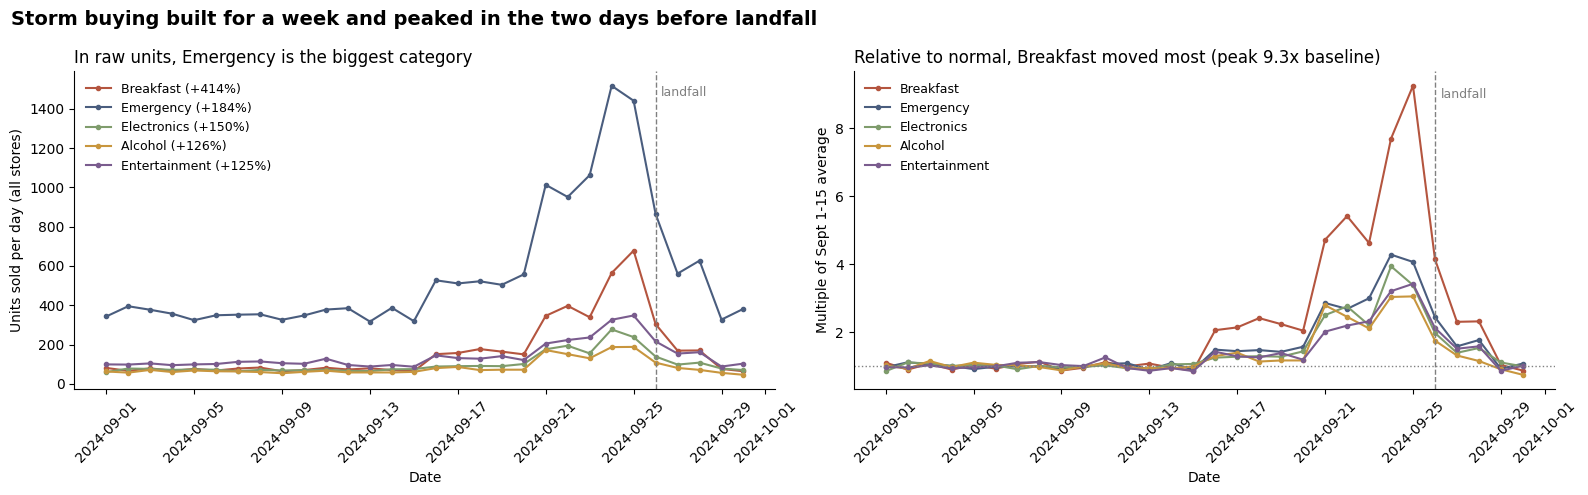

In [61]:
# TODO: the numbers

# Only use rows that have a timestamp and aren't returns
t = txn[~txn['ts_missing'] & ~txn['is_return']]

# Total units sold each day for each category
by_cat = t.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')

# Normal days = Sept 1-15, storm week = Sept 19-25 (the 7 days before landfall)
base  = by_cat.loc['2024-09-01':'2024-09-15'].mean()
surge = by_cat.loc['2024-09-19':'2024-09-25'].mean()

# Compare the storm week to normal days for every category
summary = pd.DataFrame({
    'baseline_per_day': base.round(1),
    'surge_per_day':    surge.round(1),
    'pct_increase':     ((surge / base - 1) * 100).round(0),
}).sort_values('pct_increase', ascending=False)
print(summary)

# Keep the 5 categories that went up the most
top5 = summary.index[:5]
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#7a5c8e']

# Divide each category by its normal day, so 1.0 means a normal day
indexed = by_cat[top5] / base[top5]

# Left chart: actual units, right chart: compared to normal
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

for cat, color in zip(top5, colors):
    ax1.plot(by_cat.index, by_cat[cat], marker='o', ms=3, color=color,
             label=f"{cat} (+{summary.loc[cat, 'pct_increase']:.0f}%)")
    ax2.plot(indexed.index, indexed[cat], marker='o', ms=3, color=color, label=cat)

ax1.set_title('In raw units, Emergency is the biggest category', loc='left', fontsize=12)
ax1.set_ylabel('Units sold per day (all stores)')

ax2.axhline(1.0, ls=':', color='gray', lw=1)   # dotted line = a normal day
ax2.set_title(f"Relative to normal, {top5[0]} moved most "
              f"(peak {indexed[top5[0]].max():.1f}x baseline)", loc='left', fontsize=12)
ax2.set_ylabel('Multiple of Sept 1-15 average')

# Same landfall line, labels, and style on both charts
for ax in (ax1, ax2):
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=6), ax.get_ylim()[1] * 0.92),
                fontsize=9, color='gray')
    ax.set_xlabel('Date')
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

fig.suptitle('Storm buying built for a week and peaked in the two days before landfall',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** All categories seem to show a similar timeline, creeping up around Sept 16 and peaking Sept 24-25 which is two days before landfall, with a sharp drop off after landfall.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Pop-Tarts SKUs merged into PT-STRAW: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
unit totals unchanged after consolidation: OK
Pop-Tarts per day: normal (Sept 1-15) 73, storm week (Sept 19-25) 377, peak 678 on Sep 25


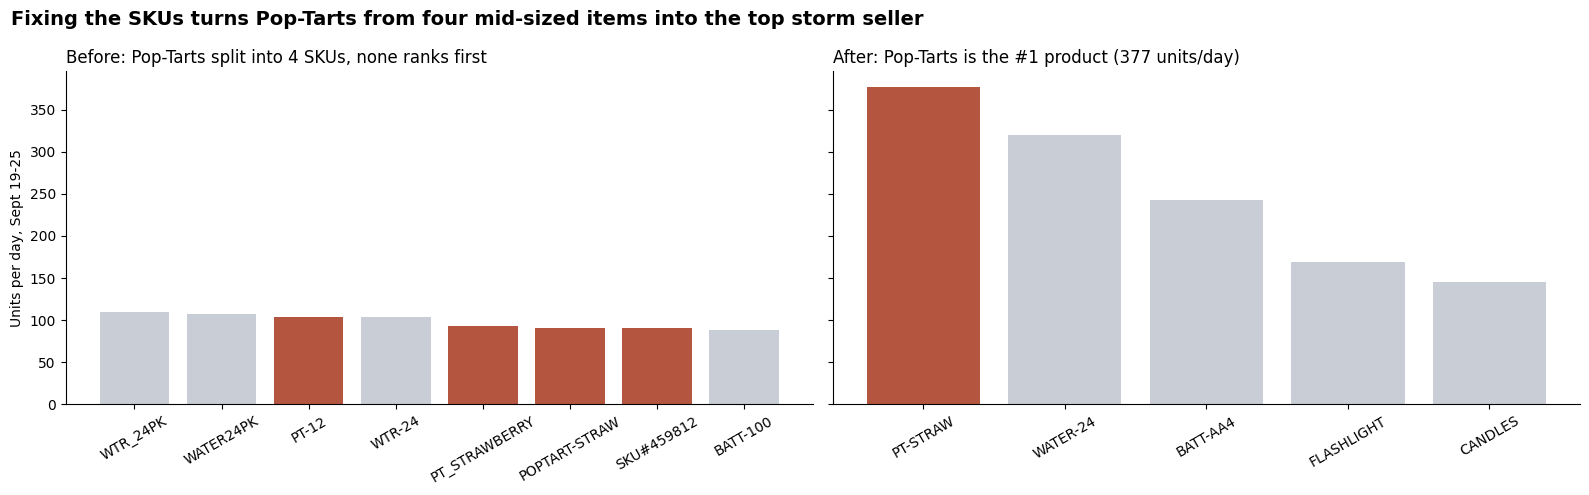

In [62]:
# Only use rows that have a timestamp and aren't returns (same as Q1)
t = txn[~txn['ts_missing'] & ~txn['is_return']]

# The Pop-Tarts family: 4 raw SKUs that are really one product
pt_skus = sorted(k for k, v in SKU_TO_PRODUCT.items() if v == 'PT-STRAW')
print('Pop-Tarts SKUs merged into PT-STRAW:', pt_skus)

# Check: merging SKUs should not change the total units
assert t.groupby('sku')['quantity'].sum().sum() == t.groupby('product_id')['quantity'].sum().sum()
print('unit totals unchanged after consolidation: OK')

# True daily volume of Pop-Tarts after merging
pt_daily = t[t['product_id'] == 'PT-STRAW'].groupby('date')['quantity'].sum()
print(f"Pop-Tarts per day: normal (Sept 1-15) {pt_daily.loc[:'2024-09-15'].mean():.0f}, "
      f"storm week (Sept 19-25) {pt_daily.loc['2024-09-19':'2024-09-25'].mean():.0f}, "
      f"peak {pt_daily.max():.0f} on {pt_daily.idxmax():%b %d}")

# Storm week (7 days before landfall): average units per day
storm = t[(t['date'] >= '2024-09-19') & (t['date'] <= '2024-09-25')]
by_sku     = (storm.groupby('sku')['quantity'].sum() / 7).sort_values(ascending=False).head(8)
by_product = (storm.groupby('product_id')['quantity'].sum() / 7).sort_values(ascending=False).head(5)

# Left: what you see with raw SKUs, right: after merging into products
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), sharey=True)   # same scale so the sizes compare fairly

colors1 = ['#b4553f' if s in pt_skus else '#c9cdd6' for s in by_sku.index]
ax1.bar(by_sku.index, by_sku.values, color=colors1)
ax1.set_title('Before: Pop-Tarts split into 4 SKUs, none ranks first', loc='left', fontsize=12)
ax1.set_ylabel('Units per day, Sept 19-25')
ax1.tick_params(axis='x', rotation=30)

colors2 = ['#b4553f' if p == 'PT-STRAW' else '#c9cdd6' for p in by_product.index]
ax2.bar(by_product.index, by_product.values, color=colors2)
ax2.set_title(f"After: Pop-Tarts is the #1 product ({by_product['PT-STRAW']:.0f} units/day)",
              loc='left', fontsize=12)
ax2.tick_params(axis='x', rotation=30)

for ax in (ax1, ax2):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

fig.suptitle('Fixing the SKUs turns Pop-Tarts from four mid-sized items into the top storm seller',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q2 answer:** Once all 4 SKU's for poptarts are combined into one product they actually sell 73 units on a normal day, 377 one day before the storm, and 678 on the Sept 25 peak. The uncleaned and matched data tells a very different story than the consolidated cleaned view. In the uncleaned set Pop-Tarts looks like ordinary items selling 90-103 units per day where none of the individual SKUs outrank water. In the cleaned set Pop Tarts are the number one product in the week, outselling water. Business decisions surrounding ordering, truck space and shelf space availability, and the forecasting would all differ if done on the individual rather than grouped SKU

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

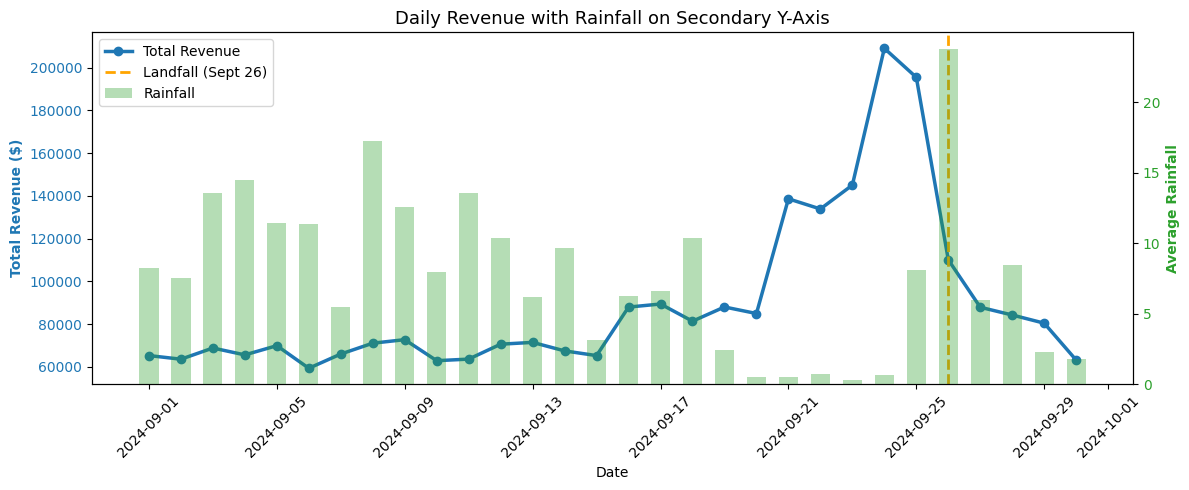

In [63]:
# Investigate daily sales volume/revenue vs. rainfall and precipitation
daily_summary = weather_live.groupby('date').agg(
    total_revenue=('total_revenue', 'sum'),
    total_units=('total_units', 'sum'),
    avg_precipitation=('precipitation_sum', 'mean'),
    avg_windspeed=('windspeed_10m_max', 'mean')
).reset_index()

# Plot Chart 4
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Revenue (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Revenue ($)', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_revenue'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Revenue'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Rainfall (Bar Chart)
ax2 = ax1.twinx()  # Moves rainfall to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Rainfall', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_precipitation'],
    color=color_rain,
    alpha=0.35,  # Transparency so revenue line remains clearly visible
    width=0.6,
    label='Rainfall'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Daily Revenue with Rainfall on Secondary Y-Axis', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

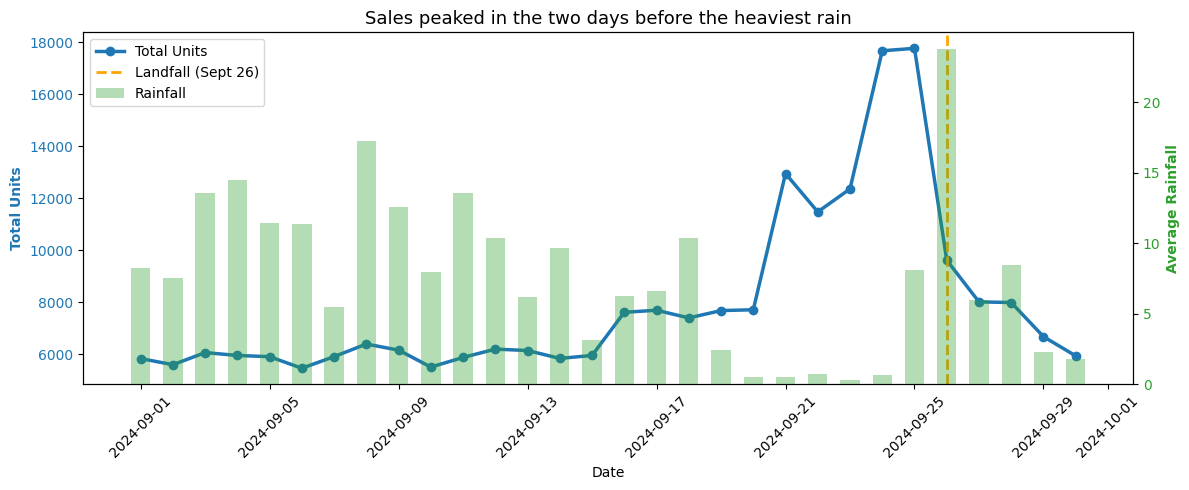

In [64]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Units (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Units', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_units'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Units'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Rainfall (Bar Chart)
ax2 = ax1.twinx()  # Moves rainfall to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Rainfall', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_precipitation'],
    color=color_rain,
    alpha=0.35,  # Transparency so units line remains clearly visible
    width=0.6,
    label='Rainfall'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Sales peaked in the two days before the heaviest rain', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

**Q3 answer, with its caveat:** There appears to be a detectable lag between the weather severity and weather indicators. Looking at wind speed and precipitation and merging based on date, both the revenue and the total units sold spike right before the worst of the weather hits. Both rainfall and windspeed appear to be accurate reactionary factors for the unit sold spike, meaning that they both accurately predict a storm. Refer to section above

The number of rows did not change when merged between the weather API data and the sales data, and zero NaN values were recorded. Refer to section 4.1 for same row values. Thus, data for each data at each store location was available

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Finished

**Q5 (signal or artifact):** Finished

### Self-check

In [65]:
progress = {
    'q1_multiple': 9,            # TODO: a number
    'q1_baseline_window': 'Sept 01 - Sept 16',   # TODO: stated explicitly
    'q2_canonical_products': 44,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 6,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 9
PASS - q1_baseline_window = Sept 01 - Sept 16
PASS - q2_canonical_products = 44
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 6
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

One thing we found surprising was how similar rainfall and windspeed when graphing across the month of September. We would've expected higher differences. But, after more consideration, this similarity is entirely expected. Both rainfall and windspeed are good indicators of a storm, so they would have similar trends.

**b)** One number you reported that you are least confident in, and why.

We are least confident in surge pattern between individual stores correlation. The numbers indicate no particular trend between distance from landfall, but cities with higher population seem to have higher surge multiples. To confirm this suspicion, we need more data on population size.

_your answer here_